# Graded Questions:
Question Group Name: 22T1_MLP_W2_PG

Total No. of Questions: 4

## Que. 1

How many features remain after applying following pipeline to the feature matrix?


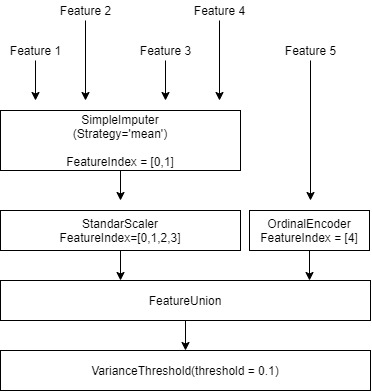

A) 5

B) 2

C) 3

D) 4

**Ans: D**

**Solution**

In [6]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer   
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer


X =[[1, 2, 3, 4, 'A'],
    [5, 6, 7, 8, 'B'],
    [9, 10, 11, 12, 'B'],
    [13, 14, 15, 16, 'A'],
    [17, 18, 19, 20, 'A'],
    [21, 22, 23, 24, 'B'],
    [25, 26, 27, 28, 'A'],]


vt = VarianceThreshold(threshold = 0.1)

numerical_pipe = ColumnTransformer(transformers=[('impute', SimpleImputer(strategy = 'mean'), [0,1,2,3])])
scale_pipe = Pipeline(steps=[('numeric', numerical_pipe),
                             ('scale', StandardScaler())])

categorical_pipe = ColumnTransformer(transformers = [('cat', OrdinalEncoder(), [4])])
complete_pipe = FeatureUnion([('numeric', scale_pipe), ('cat', categorical_pipe)])
pipe = Pipeline (steps =[('cp',complete_pipe),
                         ('varianceThreshold', VarianceThreshold(threshold =0.1))])

pipe.fit_transform(X).shape

(7, 5)

In [ ]:
data=pd.read_csv("/content/DataPreprocessingGraded_dataset.csv",na_values="?")
y=pd.DataFrame(data.pop("Target"))

num_pipe=Pipeline([("colselect",ColumnTransformer([("select","passthrough",[0,1,2,3])])),("impute",SimpleImputer()),("scale",StandardScaler())])
cat_pipe=ColumnTransformer([("encode",OrdinalEncoder(),[4])])
pipe=FeatureUnion([("numerical",num_pipe),("categorical",cat_pipe)])
tr_x=pipe.fit_transform(data)

estimator=LogisticRegression()
oe=OrdinalEncoder()
tr_y=oe.fit_transform(y)
rfe=RFE(estimator,n_features_to_select=2)

rfe.fit_transform(tr_x,tr_y.reshape(-1,))
rfe.support_

array([ True, False,  True, False, False])

In [ ]:
set_config(display="diagram")

## Que. 2

What are the two most important features computed by RFE?

Preprocess the data using pipeline shown in the diagram. Use `LogisticRegression` (with default parameters) for the `estimator`. Encode target variable via ordinal encoding.

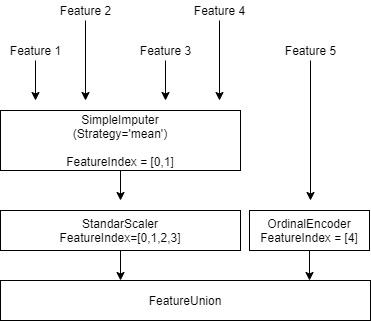


A)V1

B)V2

C)V3

D)V4

**Correct: A and C**

**Solution**

In [ ]:
%%capture
# use logistic regressor with default option for estimator
estimator = LogisticRegression()

# encode target via ordinal encoding
# reshaping y is necessary because the transformer only accepts column vector
y_encoded = OrdinalEncoder().fit_transform(y.to_numpy().reshape(-1,1)).reshape(-1,1)

# create RFE object with necessary parameters
selector = RFE(estimator, n_features_to_select=2)

# run RFE on dataset
selector = selector.fit(complete_pipe.fit_transform(X), y_encoded)

In [ ]:
# find the finally selected features
# selected features have 'True' in corresponding indices
print(selector.support_)

[ True False  True False False]


## Que. 3

What are the indices of two most important features computed by SFS (forward)?

Preprocess the data using pipeline shown in the diagram. Use `LogisticRegression` (with default parameters) for the `estimator`. Encode target variable via ordinal encoding.

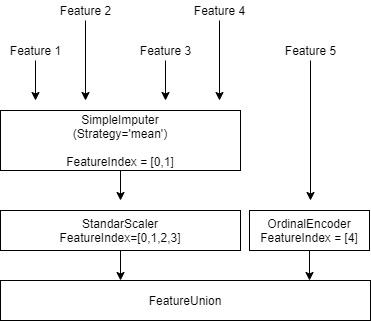

A) 0 (i.e. feature V1)

B) 1 (i.e. feature V2)

C) 2 (i.e. feature V3)

D) 3 (i.e. feature V4)

**Correct: B and D**

**Solution**

In [ ]:
%%capture
selector = SequentialFeatureSelector(estimator=LogisticRegression(),
                                     n_features_to_select=2)

# run SFS in backward direction
selector.fit(complete_pipe.fit_transform(X),
             y_encoded)

In [ ]:
# find the finally selected features
# selected features have 'True' in corresponding indices
selector.support_

array([False,  True, False,  True, False])

## Que. 4

What are the indices of two most important features computed by SFS (backward)?

Preprocess the data using pipeline shown in the diagram. Use `LogisticRegression` (with default parameters) for the `estimator`. Encode target variable via ordinal encoding.

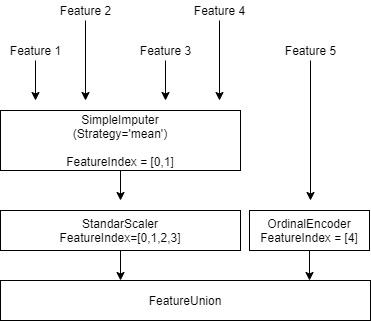

A) 0 (i.e. feature V1)

B) 1 (i.e. feature V2)

C) 2 (i.e. feature V3)

D) 3 (i.e. feature V4)

**Correct: C and D**

In [ ]:
%%capture
# intialize SFS object with appropriate parameters
selector = SequentialFeatureSelector(estimator=LogisticRegression(),
                                     n_features_to_select=2,
                                     direction='backward')

# run SFS in backward direction
selector.fit(complete_pipe.fit_transform(X),
             y_encoded)

In [ ]:
# find the finally selected features
# selected features have 'True' in corresponding indices
selector.support_

array([False, False,  True,  True, False])